In [1]:
print(f'NOrm Flow task')

NOrm Flow task


In [2]:
# PyTorch for deep learning
import torch
from torch import nn, optim, distributions
from torch.nn import functional as F

# For data visualization
import matplotlib.pyplot as plt
from pylab import rcParams

# For generating our dataset
import numpy as np
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
transform = transforms.ToTensor()

# MNIST
train_full = datasets.MNIST(root="./data_mnist", train=True,  download=True, transform=transform)
test_set   = datasets.MNIST(root="./data_mnist", train=False, download=True, transform=transform)

# For file operations
import os

# Set up plotting parameters
rcParams['figure.figsize'] = 8, 8
plt.ion()  # Interactive plotting

print("All libraries imported successfully!")
print(f"PyTorch version: {torch.__version__}")
print(f"Using device: {'CUDA' if torch.cuda.is_available() else 'CPU'}")


100.0%
100.0%
100.0%
100.0%

All libraries imported successfully!
PyTorch version: 2.11.0+cu128
Using device: CUDA


In [3]:
# Training configuration
BATCH_SIZE = 256
EPOCHS = 30
LOG_INTERVAL = 50
LR = 1e-3

# Data
IN_CHANNELS = 1
IMG_SIZE = 28

# Model architecture
N_SCALES = 2            # How many times we do squeeze + split (28 -> 14 -> 7)
N_FLOW_STEPS = 4        # Coupling layers per scale
HIDDEN_CHANNELS = 64    # Channels in the hidden layers of the coupling CNN
N_RES_BLOCKS = 2        # Depth of the coupling CNN (residual blocks)
KERNEL_SIZE = 3         # Kernel size of convolutions
PADDING = 1             # Keeps spatial size unchanged for kernel 3

# Visualization settings
SAVE_PLT_INTERVAL = 1   # How often to save plots
N_SAMPLES = 64          # How many images to generate for visualization
TEMPERATURE = 0.7       # Scale of z when sampling (lower = cleaner, less diverse)

# Set up device (use GPU if available, otherwise CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print("🔧 Configuration set up!")
print(f"   Batch size: {BATCH_SIZE}")
print(f"   Epochs: {EPOCHS}")
print(f"   Scales: {N_SCALES}, flow steps per scale: {N_FLOW_STEPS}")
print(f"   Hidden channels: {HIDDEN_CHANNELS}")
print(f"   Device: {device}")

🔧 Configuration set up!
   Batch size: 256
   Epochs: 30
   Scales: 2, flow steps per scale: 4
   Hidden channels: 64
   Device: cuda


In [4]:
train_set, val_set = random_split(
    train_full, [55000, 5000],
    generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

In [5]:
type(train_loader)
for x, y in train_loader:
    print(x.shape)
    print(y.shape)
    break

torch.Size([256, 1, 28, 28])
torch.Size([256])


Train: 55000, Val: 5000, Test: 10000
Batch shape: torch.Size([256, 1, 28, 28])


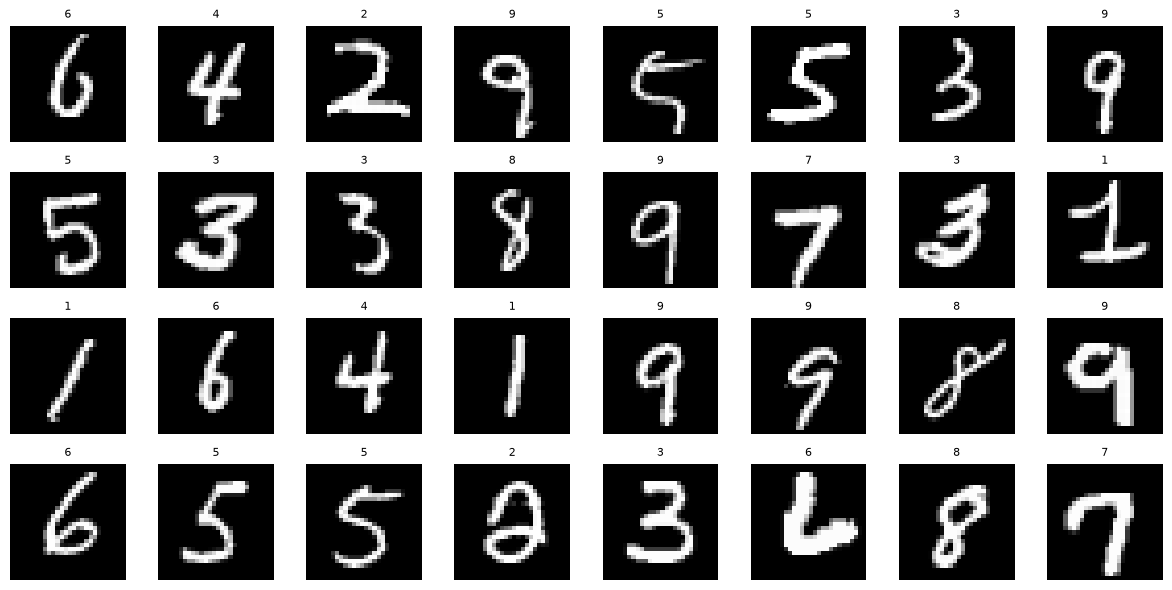

In [6]:
print(f"Train: {len(train_set)}, Val: {len(val_set)}, Test: {len(test_set)}")

x, y = next(iter(train_loader))
print(f"Batch shape: {x.shape}")

fig, axes = plt.subplots(4, 8, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(x[i, 0], cmap='gray')
    ax.set_title(int(y[i]), fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.show()

In [7]:
kwargs = {'num_workers': 1, 'pin_memory': True} if device.type == 'cuda' else {}

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, **kwargs)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False, **kwargs)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False, **kwargs)

x, y = next(iter(train_loader))
print(len(train_loader), len(val_loader), len(test_loader))
print(x.shape, x.min().item(), x.max().item())

215 20 40
torch.Size([256, 1, 28, 28]) 0.0 1.0


with the help of claude I made myself a few diagrams to understand the blocks of RealNVP
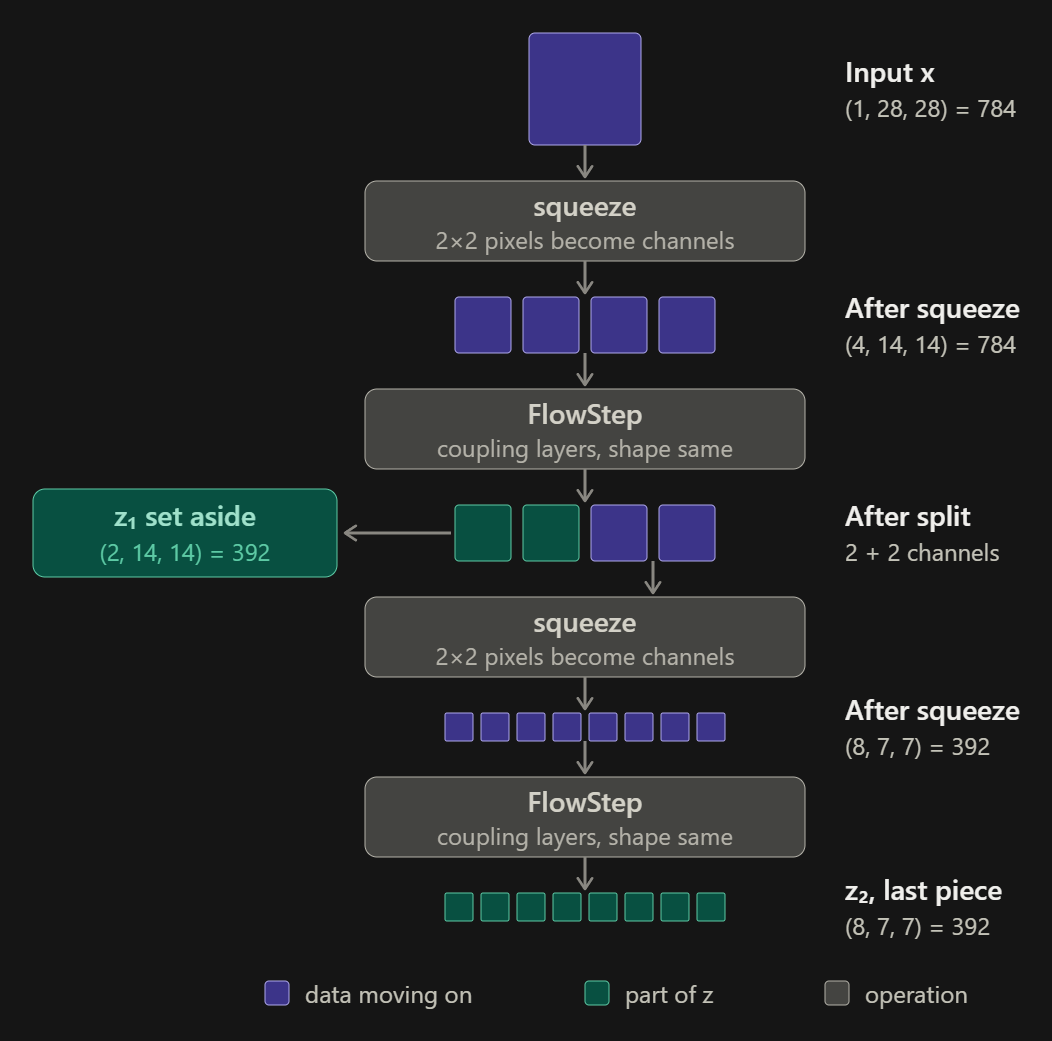

so here it is pretty clear that after each flow step we squeeze the resulting vector even more. The question was how does each Flow step look like inside. and it's coupling layers too

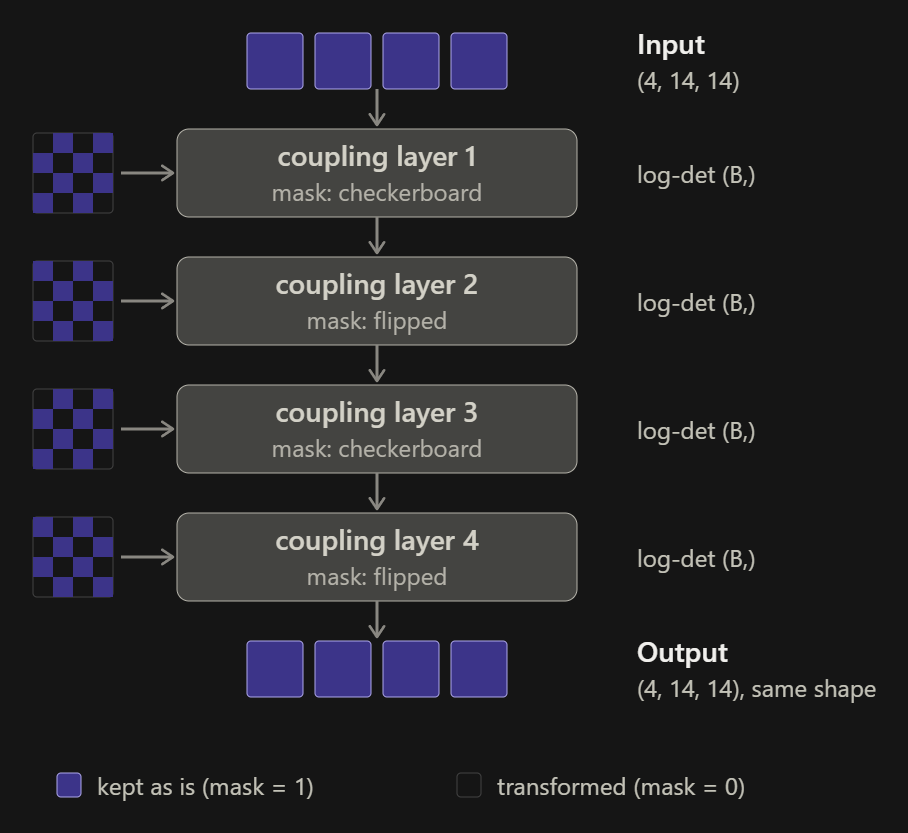

here it was easier for me to understand how can we select which parts of images do we keep and which we transform. Also it is important to mention which masks were used for that. First, the mask itself. it is a tensor of 0 and 1 with the same size as the feature map. Where the mask is 1, the value is kept as it was and is used as input for the coupling network. where the mask is 0, the value is transformed with y = x · exp(s) + t.

Inside one FlowStep the masks are:

1. Checkerboard – pixels are split like a chess board
2. Checkerboard, flipped – the same pattern with 0 and 1 swapped, so the pixels that were kept in the previous layer are now transformed.
3. Channel – the first half of the channels is kept and the second half is transformed
4. Channel, flipped – the other half of the channels is transformed.

two masks were used

next is the diagram for each coupling layer:

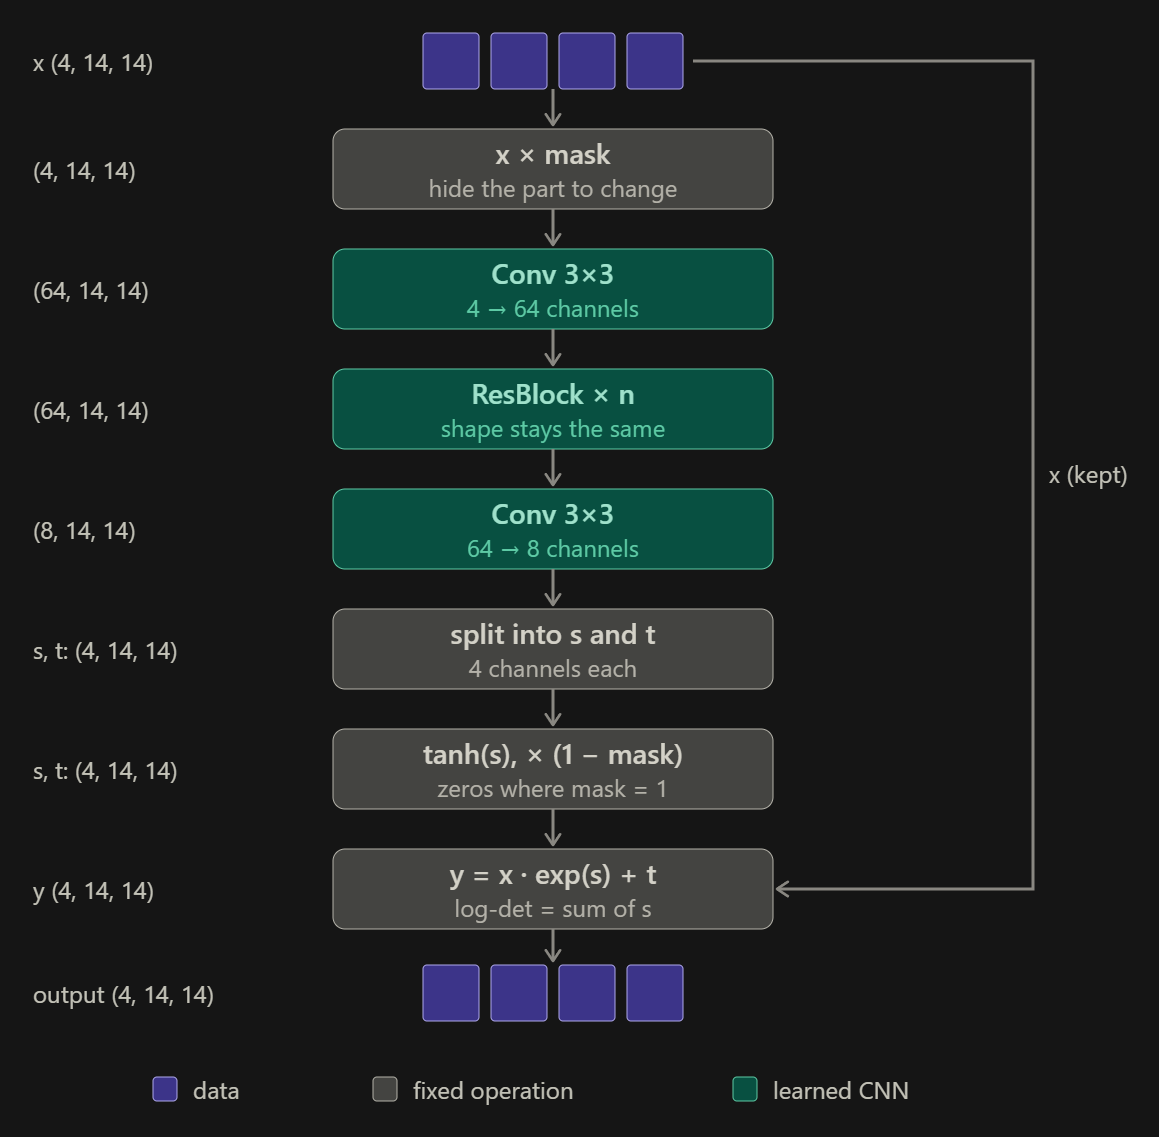

the only thing that I changed here was that I added one more learning parameter scale. and it's purpose is to scale tanh(s). Without it, tanh keeps s between -1 and 1, so one coupling layer can stretch or shrink a value at most about 2.7 times (exp(1)). That turned out to be too little for MNIST: the black background pixels all sit in a tiny interval of width about 1/256, and to turn them into something that looks like N(0, 1) the flow has to stretch them roughly 250 times. With only a few layers the model hit this ceiling, the loss stopped improving and the samples did not look like digits

s = self.scale * torch.tanh(s_from_network)

In [8]:
class ResBlock(nn.Module):
    def __init__(self, channels, kernel_size, padding):
        super().__init__()
        self.net = nn.Sequential(
            nn.ReLU(),
            nn.Conv2d(channels, channels, kernel_size, padding=padding),

            nn.ReLU(),
            nn.Conv2d(channels, channels, kernel_size, padding=padding),
        )
    def forward(self, x):
        return x + self.net(x)

class CouplingLayer(nn.Module):
    def __init__(self, in_channels, hidden_channels, n_res_blocks, mask, kernel_size=3, padding=1):
        super().__init__()
        self.register_buffer('mask', mask)
        self.inp = nn.Conv2d(in_channels, hidden_channels, kernel_size, padding=padding)
        self.blocks = nn.Sequential(*[ResBlock(hidden_channels, kernel_size, padding) for _ in range(n_res_blocks)])
        self.out = nn.Conv2d(hidden_channels, 2 * in_channels, kernel_size, padding=padding)
        nn.init.zeros_(self.out.weight)
        nn.init.zeros_(self.out.bias)
        self.scale = nn.Parameter(torch.ones(1, in_channels, 1, 1))
        
    def st(self, x_masked):
        h = self.out(F.relu(self.blocks(self.inp(x_masked))))
        s, t = h.chunk(2, dim=1)
        return self.scale * torch.tanh(s) * (1 - self.mask), t * (1 - self.mask)
    def forward(self, x):
        s, t = self.st(x * self.mask)
        return x * torch.exp(s) + t, s.sum(dim=(1, 2, 3))
    def inverse(self, y):
        s, t = self.st(y * self.mask)
        return (y - t) * torch.exp(-s)

def checkerboard_mask(h, w, flip=False):
    m = ((torch.arange(h).view(-1, 1) + torch.arange(w).view(1, -1)) % 2).float().view(1, 1, h, w)
    return 1 - m if flip else m

def channel_mask(c, flip=False):
    m = torch.zeros(1, c, 1, 1)
    m[:, : c // 2] = 1
    return 1 - m if flip else m

In [9]:
class FlowStep(nn.Module):
    def __init__(self, in_channels, hidden_channels, n_res_blocks, n_layers, size, mask_type='checkerboard'):
        super().__init__()
        assert n_layers % 2 == 0
        layers = []
        for i in range(n_layers):
            flip = i % 2 == 1
            if (i // 2) % 2 == 0:
                mask = checkerboard_mask(size, size, flip)
            else:
                mask = channel_mask(in_channels, flip)
            layers.append(CouplingLayer(in_channels, hidden_channels, n_res_blocks, mask))
        self.layers = nn.ModuleList(layers)
    def forward(self, x):
        ldj_sum = 0
        for layer in self.layers:
            x, ldj = layer(x)
            ldj_sum = ldj_sum + ldj
        return x, ldj_sum
    def inverse(self, z):
        for layer in reversed(self.layers):
            z = layer.inverse(z)
        return z

In [10]:
# here I also tried to understand how we transform vectors and how shapes change

import math

# Mini example for squeeze, a 4x4 image (B=1, C=1):
#
#  0  1 |  2  3          after squeeze (1, 4, 2, 2):
#  4  5 |  6  7          channel 0: [[ 0,  2], [ 8, 10]]   top-left pixel of every block
# ------+------          channel 1: [[ 1,  3], [ 9, 11]]   top-right
#  8  9 | 10 11          channel 2: [[ 4,  6], [12, 14]]   bottom-left
# 12 13 | 14 15          channel 3: [[ 5,  7], [13, 15]]   bottom-right
#
# Every 2x2 block became one "pixel" with 4 channels: 16 numbers before, 16 after.

def squeeze(x):
    b, c, h, w = x.shape                                # (B, 1, 28, 28)
    x = x.view(b, c, h // 2, 2, w // 2, 2)              # (B, 1, 14, 2, 14, 2)  axes: [b, c, block_row, row_in_block, block_col, col_in_block]
    x = x.permute(0, 1, 3, 5, 2, 4).contiguous()        # (B, 1, 2, 2, 14, 14)  axes: [b, c, row_in_block, col_in_block, block_row, block_col]
    return x.view(b, c * 4, h // 2, w // 2)             # (B, 4, 14, 14)        the two size-2 axes merged into channels: channel = row_in_block * 2 + col_in_block

def unsqueeze(x):
    b, c, h, w = x.shape                                # (B, 4, 14, 14)
    x = x.view(b, c // 4, 2, 2, h, w)                   # (B, 1, 2, 2, 14, 14)  channels split back into (row_in_block, col_in_block)
    x = x.permute(0, 1, 4, 2, 5, 3).contiguous()        # (B, 1, 14, 2, 14, 2)  axes: [b, c, block_row, row_in_block, block_col, col_in_block]
    return x.view(b, c // 4, h * 2, w * 2)              # (B, 1, 28, 28)        row = block_row * 2 + row_in_block, same for columns


def gaussian_log_prob(z):
    return distributions.Normal(0, 1).log_prob(z).sum(dim=(1, 2, 3))

In [11]:
class RealNVP(nn.Module):
    def __init__(self, in_channels, img_size, hidden_channels, n_res_blocks, n_scales, n_flow_steps, mask_type='checkerboard'):
        super().__init__()
        assert img_size % (2 ** n_scales) == 0
        self.steps = nn.ModuleList()
        self.z_shapes = []
        c, s = in_channels, img_size
        for i in range(n_scales):
            c, s = c * 4, s // 2
            self.steps.append(FlowStep(c, hidden_channels, n_res_blocks, n_flow_steps, s, mask_type))
            if i < n_scales - 1:
                c = c // 2
            self.z_shapes.append((c, s, s))
    def forward(self, x):
        zs = []
        ldj_sum = 0
        for i, step in enumerate(self.steps):
            x, ldj = step(squeeze(x))
            ldj_sum = ldj_sum + ldj
            if i < len(self.steps) - 1:
                z, x = x.chunk(2, dim=1)
                zs.append(z)
        zs.append(x)
        return zs, ldj_sum
    def log_prob(self, x):
        zs, ldj = self(x)
        return sum(gaussian_log_prob(z) for z in zs) + ldj
    def inverse(self, zs):
        x = zs[-1]
        for i in reversed(range(len(self.steps))):
            if i < len(self.steps) - 1:
                x = torch.cat([zs[i], x], dim=1)
            x = unsqueeze(self.steps[i].inverse(x))
        return x
    @torch.no_grad()
    def sample(self, n, temperature=1.0):
        device = next(self.parameters()).device
        zs = [temperature * torch.randn(n, *shape, device=device) for shape in self.z_shapes]
        return self.inverse(zs)

In [12]:
def preprocess(x):
    x = torch.round(x * 255)
    return (x + torch.rand_like(x)) / 256 - 0.5

def postprocess(x):
    return (x + 0.5).clamp(0, 1)

In [13]:
model = RealNVP(IN_CHANNELS, IMG_SIZE, HIDDEN_CHANNELS, N_RES_BLOCKS, N_SCALES, N_FLOW_STEPS).to(device)
optimizer = optim.Adam(model.parameters(), lr=LR)
print(sum(p.numel() for p in model.parameters()))

x, _ = next(iter(train_loader))
x = preprocess(x.to(device))
with torch.no_grad():
    print(x.min().item(), x.max().item())
    print(-model.log_prob(x).mean().item())

1265296
-0.4999999701976776 0.49999988079071045
810.6417236328125


In [14]:
def train(epoch):
    model.train()
    total = 0
    for i, (x, _) in enumerate(train_loader):
        x = preprocess(x.to(device))
        loss = -model.log_prob(x).mean()
        optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 100.0)
        optimizer.step()
        total += loss.item() * x.size(0)
        if i % LOG_INTERVAL == 0:
            print(f'epoch {epoch} [{i}/{len(train_loader)}] loss {loss.item():.2f}')
    return total / len(train_loader.dataset)

In [15]:
@torch.no_grad()
def evaluate(loader):
    model.eval()
    total = 0
    for x, _ in loader:
        x = preprocess(x.to(device))
        total += -model.log_prob(x).sum().item()
    return total / len(loader.dataset)

In [16]:
import torchvision.utils as vutils

def sample(epoch, n=64, temperature=TEMPERATURE):
    model.eval()
    imgs = postprocess(model.sample(n, temperature)).cpu()
    grid = vutils.make_grid(imgs, nrow=8)
    plt.figure(figsize=(5, 5))
    plt.imshow(grid.permute(1, 2, 0))
    plt.title(f'epoch {epoch}, temperature {temperature}')
    plt.axis('off')
    if epoch % SAVE_PLT_INTERVAL == 0:
        os.makedirs('results_mnsit', exist_ok=True)
        plt.savefig(f'results_mnsit/samples_{epoch}.png')
    plt.show()

Starting training...

Epoch 1/30
------------------------------
epoch 1 [0/215] loss 810.55
epoch 1 [50/215] loss -717.62
epoch 1 [100/215] loss -961.45
epoch 1 [150/215] loss -1129.07
epoch 1 [200/215] loss -1231.94


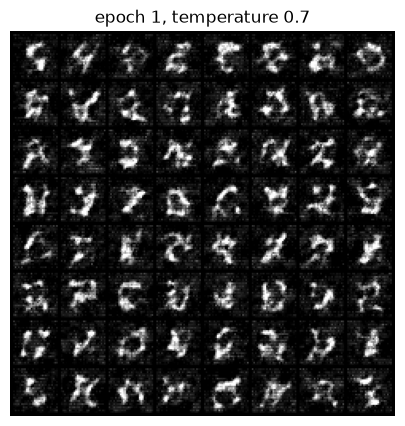

Epoch 1 summary:
   Train loss: -868.36
   Val loss:   -1226.52
   Saved best model

Epoch 2/30
------------------------------
epoch 2 [0/215] loss -1236.34
epoch 2 [50/215] loss -1372.28
epoch 2 [100/215] loss -1412.55
epoch 2 [150/215] loss -1438.76
epoch 2 [200/215] loss -1510.53


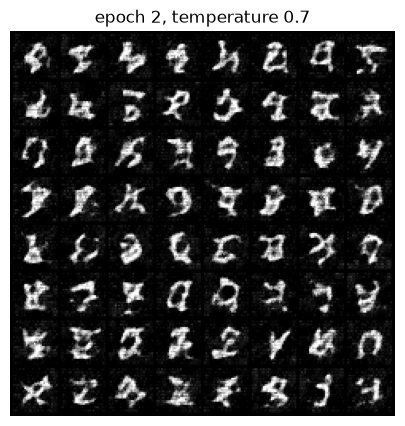

Epoch 2 summary:
   Train loss: -1395.01
   Val loss:   -1531.60
   Saved best model

Epoch 3/30
------------------------------
epoch 3 [0/215] loss -1523.72
epoch 3 [50/215] loss -1591.29
epoch 3 [100/215] loss -1643.54
epoch 3 [150/215] loss -1695.47
epoch 3 [200/215] loss -1650.89


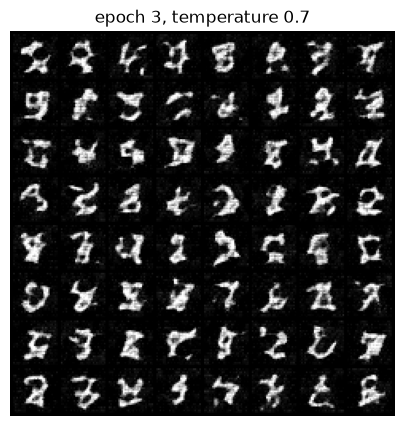

Epoch 3 summary:
   Train loss: -1622.87
   Val loss:   -1736.26
   Saved best model

Epoch 4/30
------------------------------
epoch 4 [0/215] loss -1743.48
epoch 4 [50/215] loss -1718.02
epoch 4 [100/215] loss -1761.60
epoch 4 [150/215] loss -1814.88
epoch 4 [200/215] loss -1868.93


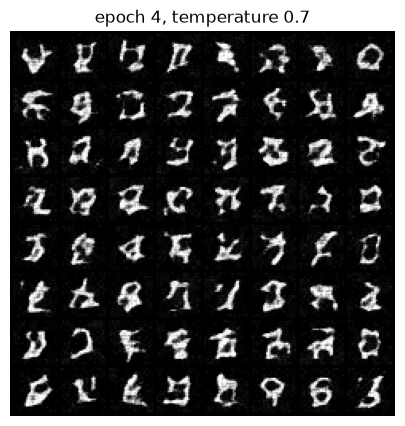

Epoch 4 summary:
   Train loss: -1788.30
   Val loss:   -1900.17
   Saved best model

Epoch 5/30
------------------------------
epoch 5 [0/215] loss -1896.94
epoch 5 [50/215] loss -1914.57
epoch 5 [100/215] loss -1957.44
epoch 5 [150/215] loss -1883.06
epoch 5 [200/215] loss -2049.89


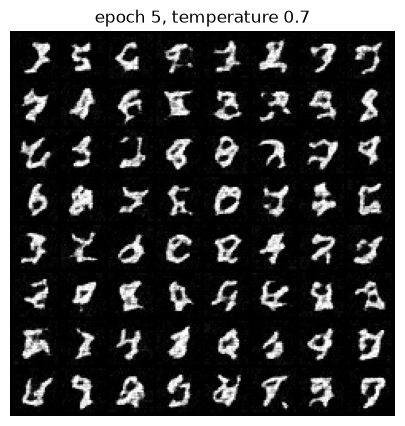

Epoch 5 summary:
   Train loss: -1936.77
   Val loss:   -2020.46
   Saved best model

Epoch 6/30
------------------------------
epoch 6 [0/215] loss -2006.27
epoch 6 [50/215] loss -2020.16
epoch 6 [100/215] loss -2105.48
epoch 6 [150/215] loss -2109.72
epoch 6 [200/215] loss -2158.61


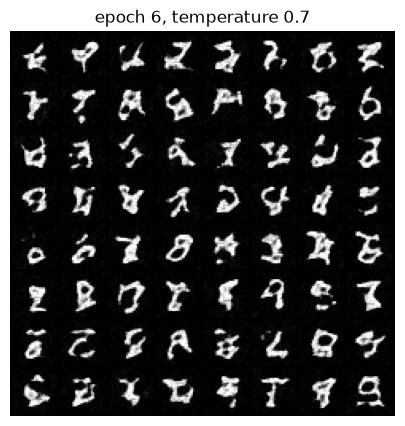

Epoch 6 summary:
   Train loss: -2067.30
   Val loss:   -2166.91
   Saved best model

Epoch 7/30
------------------------------
epoch 7 [0/215] loss -2157.77
epoch 7 [50/215] loss -2105.65
epoch 7 [100/215] loss -2193.28
epoch 7 [150/215] loss -2170.99
epoch 7 [200/215] loss -2177.96


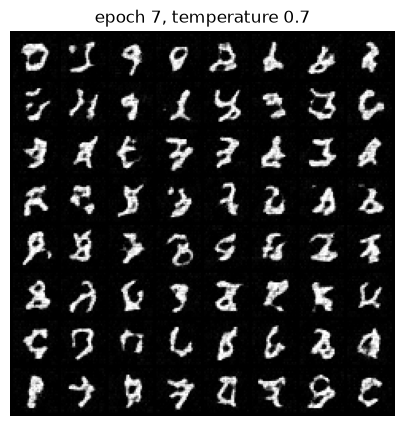

Epoch 7 summary:
   Train loss: -2178.09
   Val loss:   -2236.61
   Saved best model

Epoch 8/30
------------------------------
epoch 8 [0/215] loss -2248.81
epoch 8 [50/215] loss -2233.04
epoch 8 [100/215] loss -2288.28
epoch 8 [150/215] loss -2290.57
epoch 8 [200/215] loss -2251.68


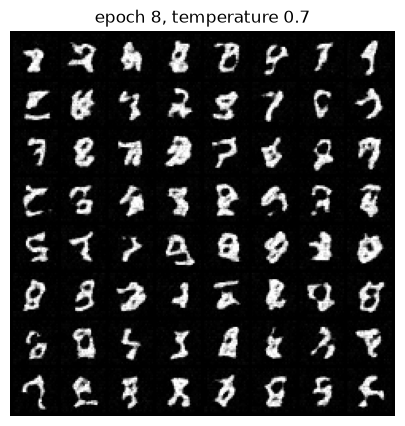

Epoch 8 summary:
   Train loss: -2271.24
   Val loss:   -2284.42
   Saved best model

Epoch 9/30
------------------------------
epoch 9 [0/215] loss -2293.89
epoch 9 [50/215] loss -2367.50
epoch 9 [100/215] loss -2363.87
epoch 9 [150/215] loss -2337.43
epoch 9 [200/215] loss -2340.59


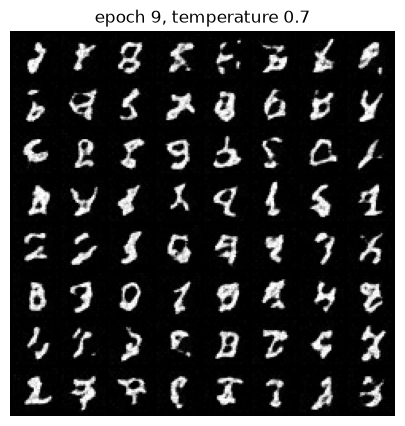

Epoch 9 summary:
   Train loss: -2351.15
   Val loss:   -2392.09
   Saved best model

Epoch 10/30
------------------------------
epoch 10 [0/215] loss -2385.44
epoch 10 [50/215] loss -2417.16
epoch 10 [100/215] loss -2424.87
epoch 10 [150/215] loss -2415.40
epoch 10 [200/215] loss -2419.43


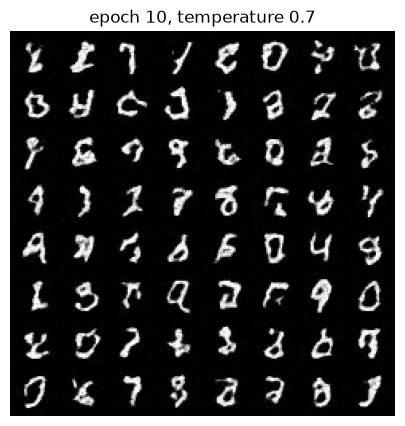

Epoch 10 summary:
   Train loss: -2407.78
   Val loss:   -2389.18

Epoch 11/30
------------------------------
epoch 11 [0/215] loss -2398.69
epoch 11 [50/215] loss -2418.98
epoch 11 [100/215] loss -2506.55
epoch 11 [150/215] loss -2521.98
epoch 11 [200/215] loss -2498.46


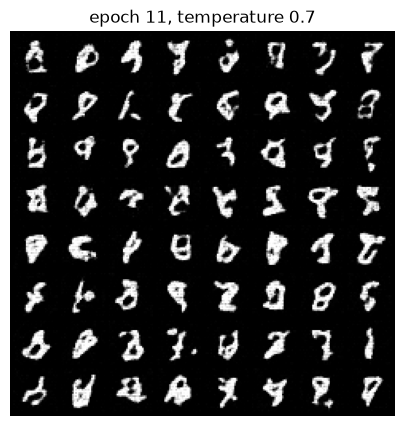

Epoch 11 summary:
   Train loss: -2464.67
   Val loss:   -2455.28
   Saved best model

Epoch 12/30
------------------------------
epoch 12 [0/215] loss -2451.53
epoch 12 [50/215] loss -2508.52
epoch 12 [100/215] loss -2452.86
epoch 12 [150/215] loss -2558.21
epoch 12 [200/215] loss -2596.91


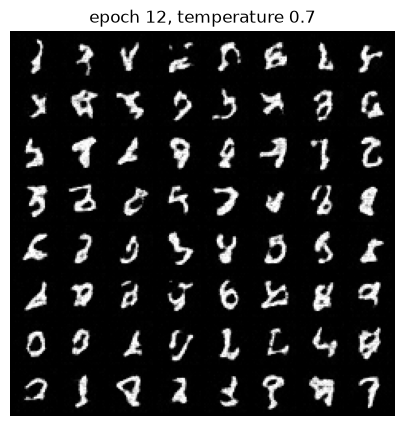

Epoch 12 summary:
   Train loss: -2519.80
   Val loss:   -2590.87
   Saved best model

Epoch 13/30
------------------------------
epoch 13 [0/215] loss -2586.20
epoch 13 [50/215] loss -2446.44
epoch 13 [100/215] loss -2529.74
epoch 13 [150/215] loss -2586.56
epoch 13 [200/215] loss -2623.10


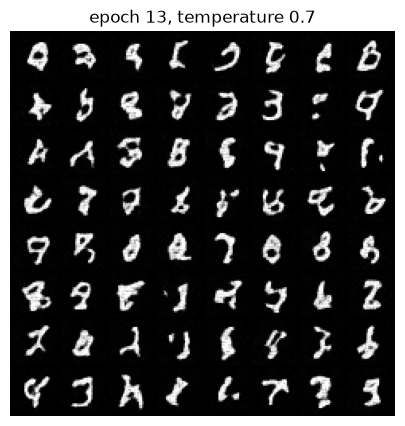

Epoch 13 summary:
   Train loss: -2558.48
   Val loss:   -2588.33

Epoch 14/30
------------------------------
epoch 14 [0/215] loss -2594.61
epoch 14 [50/215] loss -2596.25
epoch 14 [100/215] loss -2689.39
epoch 14 [150/215] loss -2579.57
epoch 14 [200/215] loss -2580.39


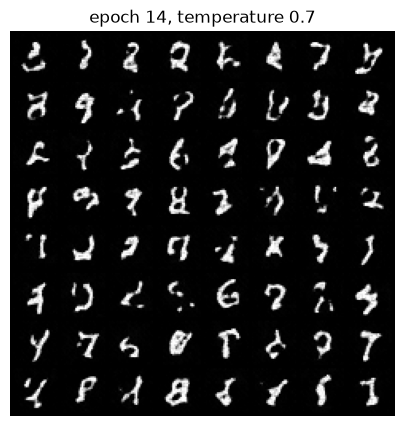

Epoch 14 summary:
   Train loss: -2621.23
   Val loss:   -2648.91
   Saved best model

Epoch 15/30
------------------------------
epoch 15 [0/215] loss -2655.19
epoch 15 [50/215] loss -2684.47
epoch 15 [100/215] loss -2721.40
epoch 15 [150/215] loss -2739.73
epoch 15 [200/215] loss -2713.03


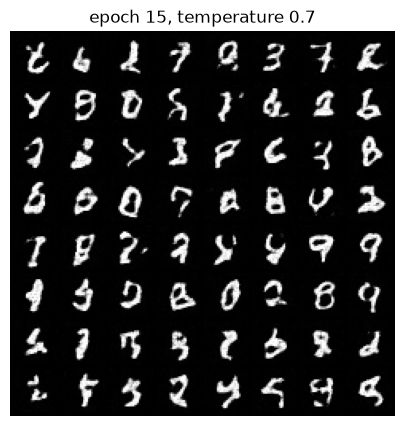

Epoch 15 summary:
   Train loss: -2680.36
   Val loss:   -2747.69
   Saved best model

Epoch 16/30
------------------------------
epoch 16 [0/215] loss -2768.45
epoch 16 [50/215] loss -2722.30
epoch 16 [100/215] loss -2705.81
epoch 16 [150/215] loss -2745.63
epoch 16 [200/215] loss -2621.75


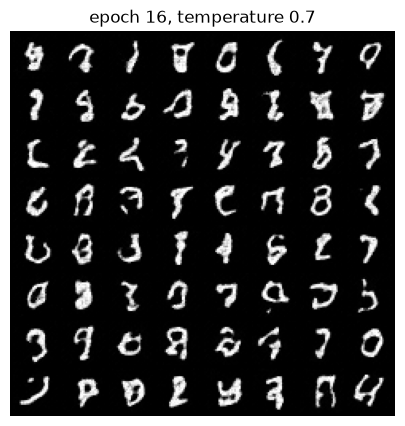

Epoch 16 summary:
   Train loss: -2707.19
   Val loss:   -2723.98

Epoch 17/30
------------------------------
epoch 17 [0/215] loss -2744.24
epoch 17 [50/215] loss -2760.03
epoch 17 [100/215] loss -2743.08
epoch 17 [150/215] loss -2819.05
epoch 17 [200/215] loss -2722.33


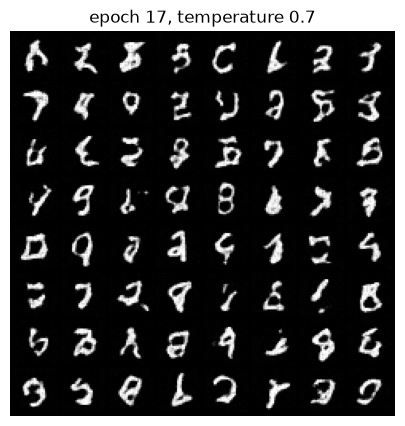

Epoch 17 summary:
   Train loss: -2750.08
   Val loss:   -2778.24
   Saved best model

Epoch 18/30
------------------------------
epoch 18 [0/215] loss -2770.30
epoch 18 [50/215] loss -2787.05
epoch 18 [100/215] loss -2688.54
epoch 18 [150/215] loss -2829.31
epoch 18 [200/215] loss -2681.34


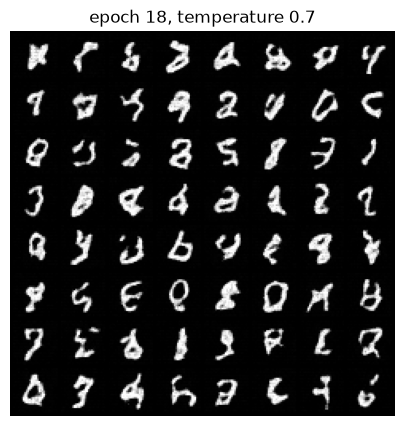

Epoch 18 summary:
   Train loss: -2771.52
   Val loss:   -2824.28
   Saved best model

Epoch 19/30
------------------------------
epoch 19 [0/215] loss -2836.95
epoch 19 [50/215] loss -2832.04
epoch 19 [100/215] loss -2847.56
epoch 19 [150/215] loss -2808.73
epoch 19 [200/215] loss -2794.64


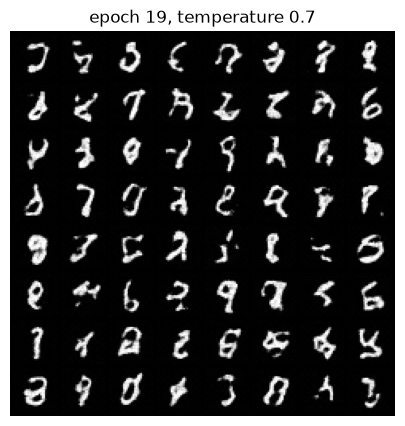

Epoch 19 summary:
   Train loss: -2828.31
   Val loss:   -2807.03

Epoch 20/30
------------------------------
epoch 20 [0/215] loss -2798.71
epoch 20 [50/215] loss -2903.82
epoch 20 [100/215] loss -2890.20
epoch 20 [150/215] loss -2902.28
epoch 20 [200/215] loss -2957.04


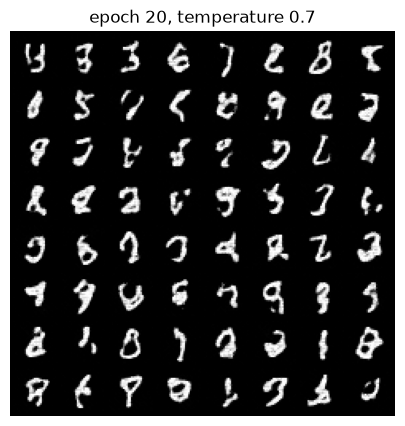

Epoch 20 summary:
   Train loss: -2890.25
   Val loss:   -2919.60
   Saved best model

Epoch 21/30
------------------------------
epoch 21 [0/215] loss -2915.78
epoch 21 [50/215] loss -2961.10
epoch 21 [100/215] loss -2997.02
epoch 21 [150/215] loss -2941.16
epoch 21 [200/215] loss -2954.72


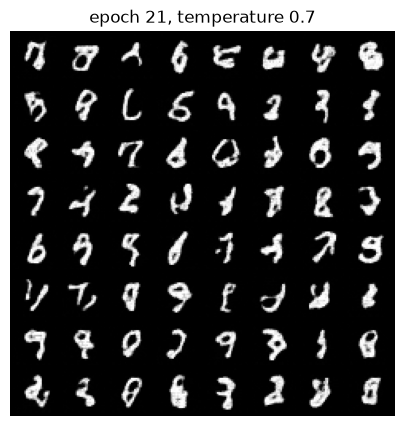

Epoch 21 summary:
   Train loss: -2932.12
   Val loss:   -2969.36
   Saved best model

Epoch 22/30
------------------------------
epoch 22 [0/215] loss -2988.09
epoch 22 [50/215] loss -2944.38
epoch 22 [100/215] loss -3022.41
epoch 22 [150/215] loss -2999.03
epoch 22 [200/215] loss -2991.97


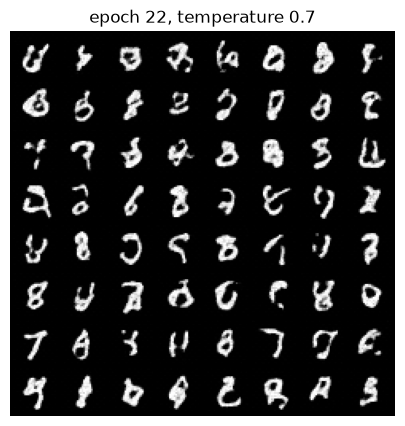

Epoch 22 summary:
   Train loss: -2970.96
   Val loss:   -2814.88

Epoch 23/30
------------------------------
epoch 23 [0/215] loss -2799.74
epoch 23 [50/215] loss -3000.16
epoch 23 [100/215] loss -2893.44
epoch 23 [150/215] loss -3045.35
epoch 23 [200/215] loss -3052.83


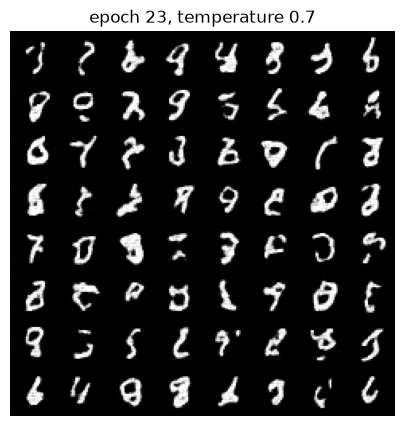

Epoch 23 summary:
   Train loss: -2985.82
   Val loss:   -3012.61
   Saved best model

Epoch 24/30
------------------------------
epoch 24 [0/215] loss -3035.68
epoch 24 [50/215] loss -2931.21
epoch 24 [100/215] loss -3015.31
epoch 24 [150/215] loss -3043.52
epoch 24 [200/215] loss -3034.15


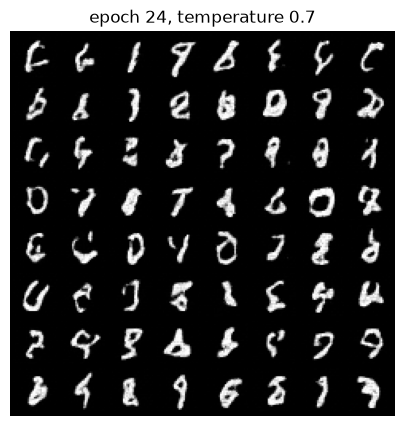

Epoch 24 summary:
   Train loss: -2991.43
   Val loss:   -3000.28

Epoch 25/30
------------------------------
epoch 25 [0/215] loss -2985.58
epoch 25 [50/215] loss -3104.78
epoch 25 [100/215] loss -3035.68
epoch 25 [150/215] loss -3098.83
epoch 25 [200/215] loss -3044.39


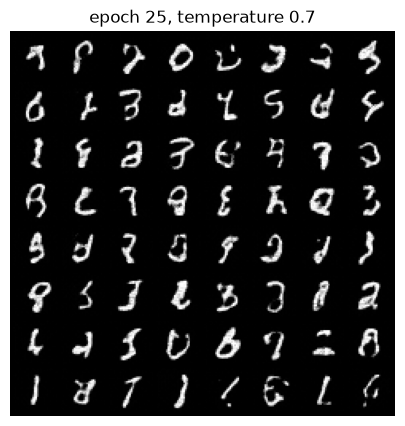

Epoch 25 summary:
   Train loss: -3039.20
   Val loss:   -3050.83
   Saved best model

Epoch 26/30
------------------------------
epoch 26 [0/215] loss -3057.95
epoch 26 [50/215] loss -3073.40
epoch 26 [100/215] loss -3078.86
epoch 26 [150/215] loss -3107.09
epoch 26 [200/215] loss -3058.88


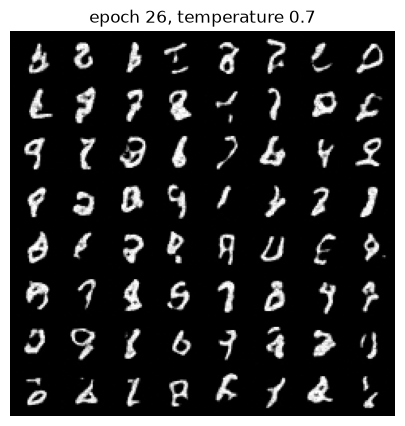

Epoch 26 summary:
   Train loss: -3038.86
   Val loss:   -3082.10
   Saved best model

Epoch 27/30
------------------------------
epoch 27 [0/215] loss -3091.62
epoch 27 [50/215] loss -3054.23
epoch 27 [100/215] loss -3076.39
epoch 27 [150/215] loss -3119.58
epoch 27 [200/215] loss -3087.27


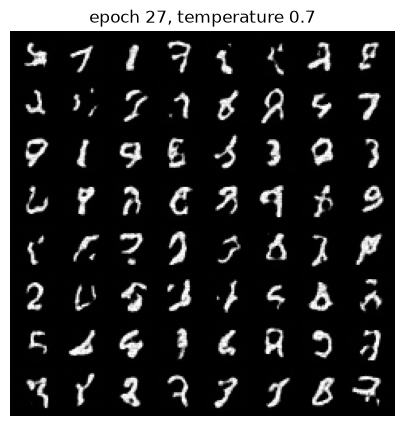

Epoch 27 summary:
   Train loss: -3083.65
   Val loss:   -3055.10

Epoch 28/30
------------------------------
epoch 28 [0/215] loss -3056.38
epoch 28 [50/215] loss -3064.52
epoch 28 [100/215] loss -2751.41
epoch 28 [150/215] loss -3094.83
epoch 28 [200/215] loss -3076.25


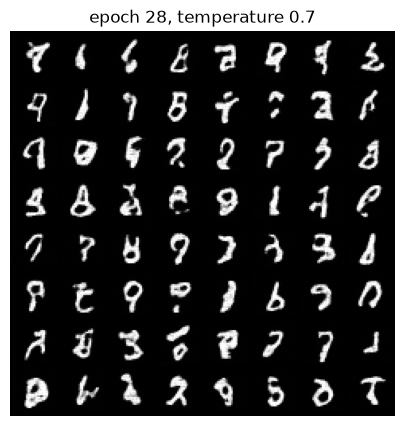

Epoch 28 summary:
   Train loss: -3055.33
   Val loss:   -3137.91
   Saved best model

Epoch 29/30
------------------------------
epoch 29 [0/215] loss -3161.40
epoch 29 [50/215] loss -3045.79
epoch 29 [100/215] loss -3153.06
epoch 29 [150/215] loss -3058.46
epoch 29 [200/215] loss -3166.81


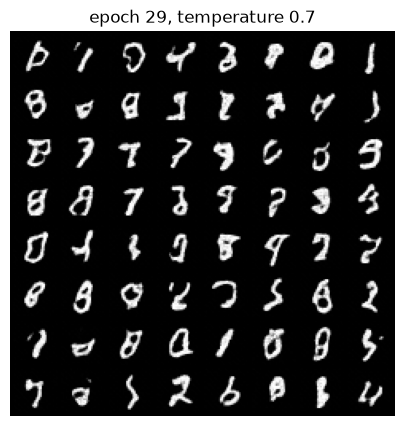

Epoch 29 summary:
   Train loss: -3079.44
   Val loss:   -3119.93

Epoch 30/30
------------------------------
epoch 30 [0/215] loss -3131.28
epoch 30 [50/215] loss -3135.70
epoch 30 [100/215] loss -3140.28
epoch 30 [150/215] loss -3097.81
epoch 30 [200/215] loss -3107.99


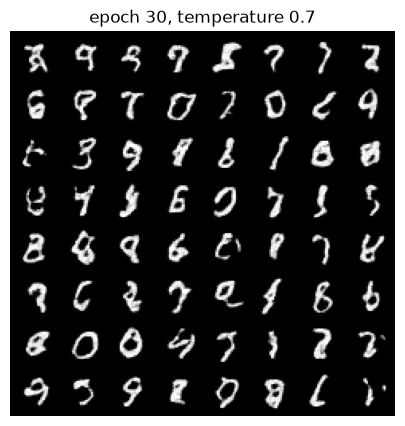

Epoch 30 summary:
   Train loss: -3116.17
   Val loss:   -3160.60
   Saved best model

Training completed!
Test loss (best model): -3158.27


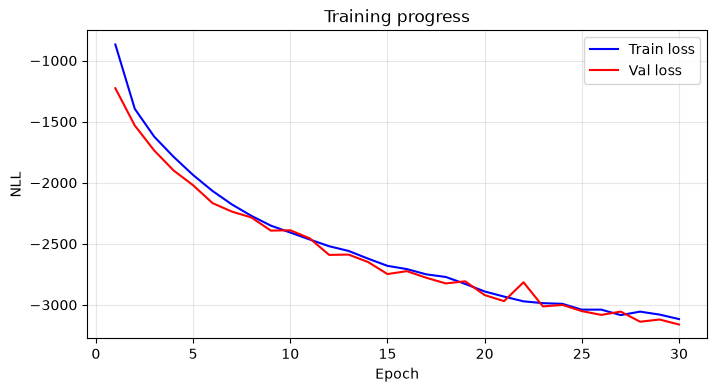

In [17]:
print('Starting training...')
print('=' * 50)
train_losses = []
val_losses = []
best_val = float('inf')
for epoch in range(1, EPOCHS + 1):
    print(f'\nEpoch {epoch}/{EPOCHS}')
    print('-' * 30)
    train_loss = train(epoch)
    val_loss = evaluate(val_loader)
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    sample(epoch)
    print(f'Epoch {epoch} summary:')
    print(f'   Train loss: {train_loss:.2f}')
    print(f'   Val loss:   {val_loss:.2f}')
    if val_loss < best_val:
        best_val = val_loss
        torch.save(model.state_dict(), 'best_mnist.pth')
        print('   Saved best model')
print('\nTraining completed!')
print('=' * 50)
model.load_state_dict(torch.load('best_mnist.pth'))
test_loss = evaluate(test_loader)
print(f'Test loss (best model): {test_loss:.2f}')
plt.figure(figsize=(8, 4))
plt.plot(range(1, EPOCHS + 1), train_losses, 'b-', label='Train loss')
plt.plot(range(1, EPOCHS + 1), val_losses, 'r-', label='Val loss')
plt.xlabel('Epoch')
plt.ylabel('NLL')
plt.title('Training progress')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

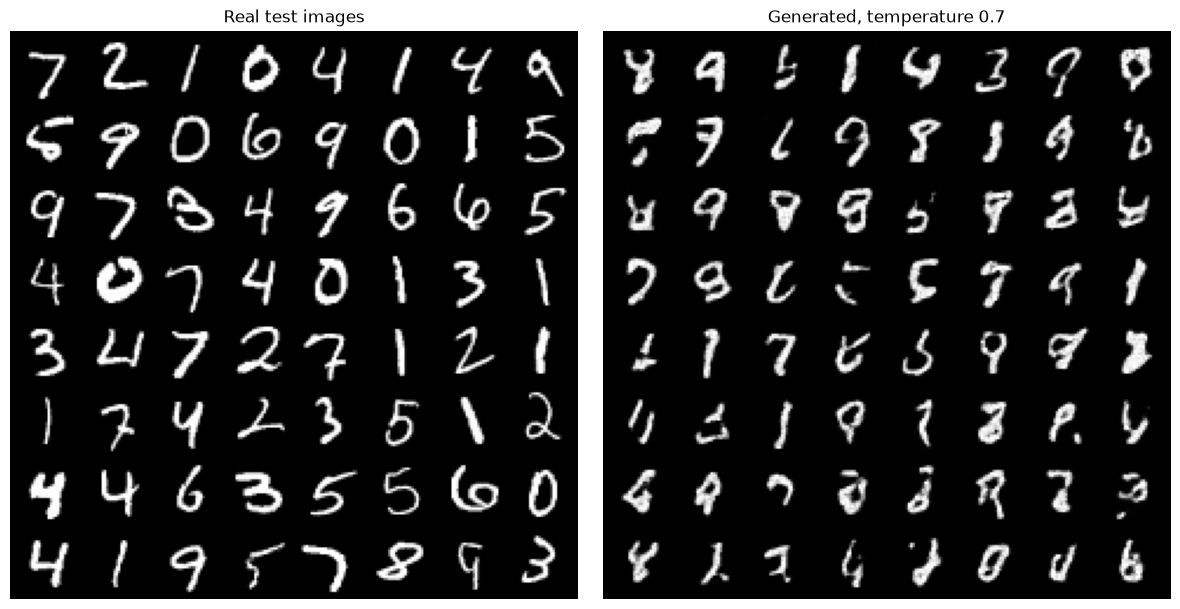

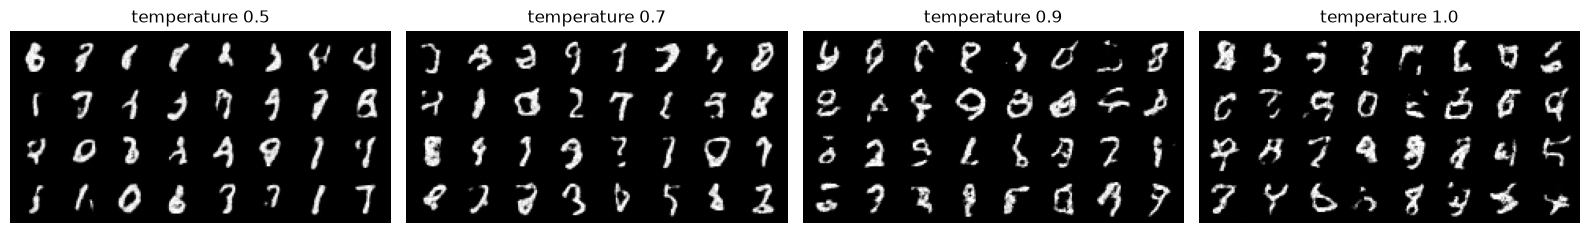

In [18]:
model.eval()
real, _ = next(iter(test_loader))
real = real[:64]
with torch.no_grad():
    generated = postprocess(model.sample(64, TEMPERATURE)).cpu()
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(vutils.make_grid(real, nrow=8).permute(1, 2, 0))
plt.title('Real test images')
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(vutils.make_grid(generated, nrow=8).permute(1, 2, 0))
plt.title(f'Generated, temperature {TEMPERATURE}')
plt.axis('off')
plt.tight_layout()
plt.show()

temps = [0.5, 0.7, 0.9, 1.0]
plt.figure(figsize=(16, 4))
for i, t in enumerate(temps):
    with torch.no_grad():
        imgs = postprocess(model.sample(32, t)).cpu()
    plt.subplot(1, len(temps), i + 1)
    plt.imshow(vutils.make_grid(imgs, nrow=8).permute(1, 2, 0))
    plt.title(f'temperature {t}')
    plt.axis('off')
plt.tight_layout()
plt.show()

torch.Size([1000, 784]) 0.0015374720096588135


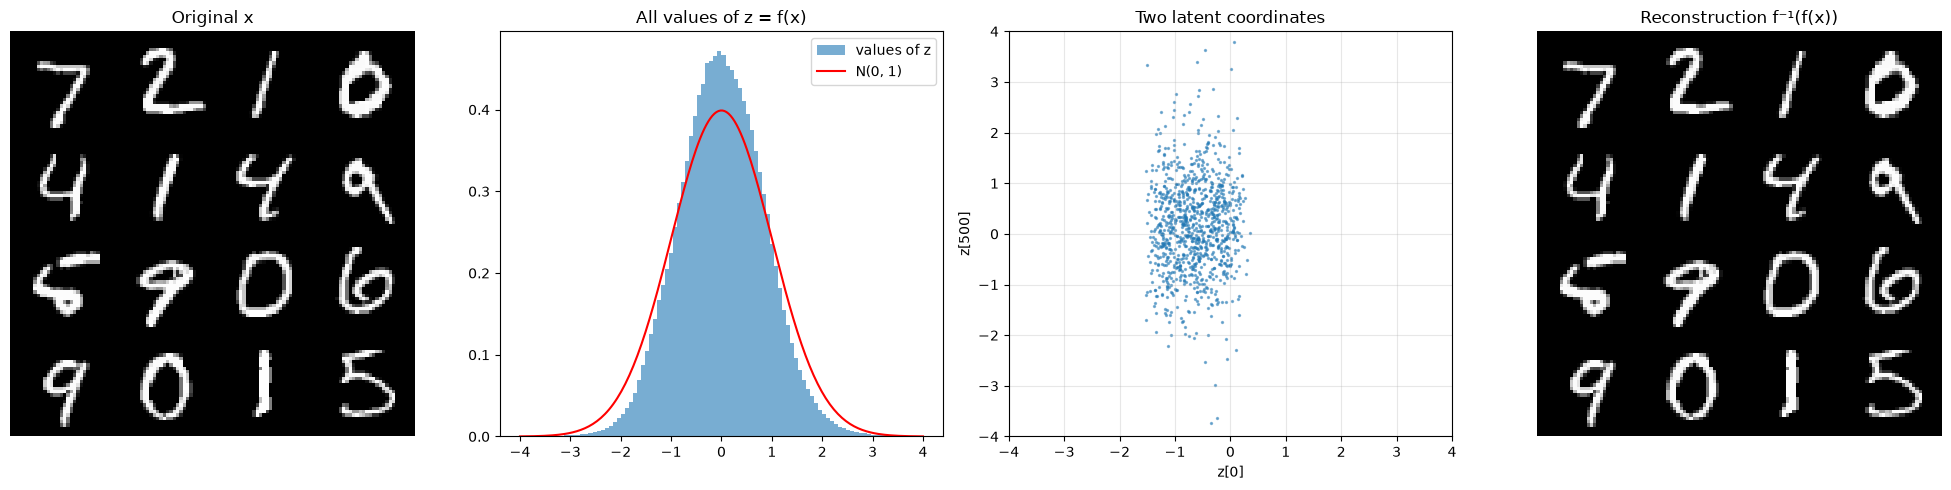

In [19]:
model.eval()
x = torch.stack([test_set[i][0] for i in range(1000)]).to(device)
x = preprocess(x)
with torch.no_grad():
    zs, _ = model(x)
    x_rec = model.inverse(zs)
z = torch.cat([zi.flatten(1) for zi in zs], dim=1).cpu()
print(z.shape, (x_rec - x).abs().max().item())
plt.figure(figsize=(20, 5))
plt.subplot(1, 4, 1)
plt.imshow(vutils.make_grid(postprocess(x[:16]).cpu(), nrow=4).permute(1, 2, 0))
plt.title('Original x')
plt.axis('off')
plt.subplot(1, 4, 2)
t = torch.linspace(-4, 4, 200)
plt.hist(z.flatten().numpy(), bins=100, range=(-4, 4), density=True, alpha=0.6, label='values of z')
plt.plot(t, torch.exp(-t ** 2 / 2) / math.sqrt(2 * math.pi), 'r', label='N(0, 1)')
plt.title('All values of z = f(x)')
plt.legend()
plt.subplot(1, 4, 3)
plt.scatter(z[:, 0], z[:, 500], s=2, alpha=0.5)
plt.xlim(-4, 4)
plt.ylim(-4, 4)
plt.xlabel('z[0]')
plt.ylabel('z[500]')
plt.title('Two latent coordinates')
plt.grid(True, alpha=0.3)
plt.subplot(1, 4, 4)
plt.imshow(vutils.make_grid(postprocess(x_rec[:16]).cpu(), nrow=4).permute(1, 2, 0))
plt.title('Reconstruction f⁻¹(f(x))')
plt.axis('off')
plt.tight_layout()
plt.show()